# C2 · Train and explain our first model

**Business Intelligence IIB423T-1 · Universidad del Desarrollo · Instructor: Tomás Fontecilla Correa**
**GROUP_01 · Matías López, Cristóbal Ramírez · C2, due 08-11-2026**

**Data source.** FONASA public GRD files `GRD_PUBLICO_2023.zip` (extracted by FONASA 04-09-2024) and `GRD_PUBLICO_2024.zip` (extracted 16-05-2025), downloaded from the Data Catalogue tab of the FONASA GRD dashboard (https://public.tableau.com/views/PropuestaTableroGRD/PropuestaTableroGRD). We use the reduced extracts produced in W1 (`GROUP_01_C1/data/extracted/`), plus the FONASA GRD dictionary and the MINSAL health facilities file (datos.gob.cl). Same inputs as W1, C1 and W2, checked by SHA-256 below.

**Route: classification.** Project line unchanged since W1: case-mix-adjusted length of stay and extreme stays in GRD-funded public hospitals.

**How to read this notebook.** 1 task definition and W2 feedback · 2 data and split (W2 preparation reused) · 3 frozen train-only preparation · 4 model and baseline · 5 validation choices · 6 final test evaluation · 7 interpretation · 8 contributions and AI use. Runtime about 3 minutes and 3 GB of RAM.

## 1. Task definition and W2 feedback

| Element | Definition |
|---|---|
| Question | At admission, can admission-time information flag the stays that will become **extreme** (longer than the cut-off of their GRD), so that discharge planning starts on day one? |
| One row | One GRD-coded inpatient stay (episode) of a GRD-funded public hospital. Not a patient, not a bed-day |
| Target | `LABEL` = 1 if LOS > GRD cut-off (Q3 + 1.5·IQR of LOS for that IR-GRD code, base-GRD fallback below 30 cases), else 0. **Positive class = extreme stay** |
| Prediction time | Admission day (t0) |
| Inputs available at t0 | Age, sex, insurance category, admission type, patient origin, admitting unit, hospital, admission month, admission weekday, transfer-in flag |
| Inputs excluded | Everything known only during the stay, at discharge or after coding: GRD code, weight, severity, mortality risk, principal and secondary diagnoses, number of diagnoses and procedures, theatre use, discharge type and unit, discharge date, LOS |

The label needs the GRD, which is assigned after discharge. That is acceptable for the **target**, which is only used to train and to evaluate; the GRD never enters the model as an input.

**W2 feedback (100/100) and what we did with it**

| # | W2 feedback | Action in C2 | Evidence |
|---|---|---|---|
| 1 | If we predict stay from admission, exclude diagnoses, classifications or final results not available at admission | Inputs are fixed in `ADM_FEATURES` (admission-time fields only). Section 2 asserts that no diagnosis, GRD, severity, procedure or discharge field is in the input matrix | Section 2, `LEAK_GUARD` assertion |
| 2 | Define and freeze, inside training, the thresholds that distinguish extreme stays, if they are estimated from the data | The GRD cut-offs are fitted on **training admissions only** (`FIT_BM`, 783 codes, 767 with a cut-off) and frozen with a SHA-256 fingerprint. Validation and test labels are produced by applying the frozen cut-offs; the fingerprint is re-checked after validation, after test and at the end | Section 3, fingerprint checks |
| — | Retained from W2 | Chronological split by admission date (T = 2024-01-01), embargo, train-only imputation and encoders | Section 2 |

In [1]:
import sys, platform, hashlib, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib, sklearn
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score, accuracy_score

SEED = 2026
BASE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()   # GROUP_01_C2/
REPO = BASE.parent
C1 = REPO / "GROUP_01_C1"
EXT, REF = C1 / "data/extracted", C1 / "data/reference"
OUT, FIG = BASE / "data/processed", BASE / "data/figures"
OUT.mkdir(parents=True, exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 80)
BLUE, ORANGE, GREY, INK, INK2, TEAL = "#2a78d6", "#eb6834", "#b8b7b2", "#0b0b0b", "#52514e", "#1a9e8f"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 8.5, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e6e3", "grid.linewidth": 0.6, "axes.axisbelow": True,
                     "axes.titlesize": 9, "axes.titlelocation": "left"})
print("Python", sys.version.split()[0], "| pandas", pd.__version__, "| numpy", np.__version__, "| scikit-learn", sklearn.__version__,
      "| matplotlib", matplotlib.__version__, "|", platform.system(), "| seed", SEED)

def sha256(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for b in iter(lambda: f.read(1 << 20), b""): h.update(b)
    return h.hexdigest()
EXPECTED_SHA = {   # published in the C1 README and checked again in W2
    "grd_2023_extracto.csv.gz": "dbe960f33b21837589bda4c989fcada57ff70de8e572714fea3f0574947d3878",
    "grd_2024_extracto.csv.gz": "7bb1f18b0a9817a578bc2c786f151c28c25965af20cf1438090832e3420ae3a0",
    "Tablas_maestras_bases_GRD.xlsx": "29da22ac27a79a5f3d62e0b97fcff79dcaf1f19908dcf517a7e6bb88f216bd8a",
    "establecimientos_datosgobcl.csv": "21c596531528078107b01388716f93d98516f7a9da1817927fd67644b7faa176"}
inputs = pd.DataFrame([{"file": str(p.relative_to(REPO)), "MB": round(p.stat().st_size/1e6, 1), "sha256": sha256(p)}
                       for p in [EXT/"grd_2023_extracto.csv.gz", EXT/"grd_2024_extracto.csv.gz",
                                 REF/"Tablas_maestras_bases_GRD.xlsx", REF/"establecimientos_datosgobcl.csv"]])
inputs["matches_C1_W2"] = [EXPECTED_SHA[Path(f).name] == h for f, h in zip(inputs.file, inputs.sha256)]
assert inputs.matches_C1_W2.all(), "Inputs differ from C1/W2"
inputs

Python 3.13.18 | pandas 3.0.5 | numpy 2.5.3 | scikit-learn 1.9.1 | matplotlib 3.11.2 | Linux | seed 2026


,file,MB,sha256,matches_C1_W2
0,GROUP_01_C1/data/extracted/grd_2023_extracto.csv.gz,40.2,dbe960f33b21837589bda4c989fcada57ff70de8e572714fea3f0574947d3878,True
1,GROUP_01_C1/data/extracted/grd_2024_extracto.csv.gz,43.2,7bb1f18b0a9817a578bc2c786f151c28c25965af20cf1438090832e3420ae3a0,True
2,GROUP_01_C1/data/reference/Tablas_maestras_bases_GRD.xlsx,0.1,29da22ac27a79a5f3d62e0b97fcff79dcaf1f19908dcf517a7e6bb88f216bd8a,True
3,GROUP_01_C1/data/reference/establecimientos_datosgobcl.csv,2.5,21c596531528078107b01388716f93d98516f7a9da1817927fd67644b7faa176,True


## 2. Data and split (W2 preparation reused)

The code below is the W2 preparation, unchanged: each file is parsed with its own date format, CMA episodes, invalid dates and invalid GRD codes are excluded with a recorded reason, and the valid inpatient stays are split by **admission date**. Train and validation keep only stays discharged before T = 2024-01-01, so every training label was known when the model would be built. The row counts must equal W2 (`w2_07_split_counts.csv`): 421,352 / 214,640 / 655,321.

In [2]:
FMT = {2023: "%d-%m-%Y", 2024: "%Y-%m-%d"}           # date format differs by file (W1 finding)
USE = ["COD_HOSPITAL", "SEXO", "PREVISION", "TIPO_PROCEDENCIA", "TIPO_INGRESO", "SERVICIOINGRESO", "HOSPPROCEDENCIA", "EDAD_ANIOS",
       "TIPO_ACTIVIDAD", "IR_29301_COD_GRD", "IR_29301_PESO", "FECHA_INGRESO", "FECHAALTA"]
parts = []
for y in (2023, 2024):
    d = pd.read_csv(EXT/f"grd_{y}_extracto.csv.gz", dtype=str, keep_default_na=False, usecols=USE)
    d["ADM"] = pd.to_datetime(d.FECHA_INGRESO, format=FMT[y], errors="coerce")
    d["DIS"] = pd.to_datetime(d.FECHAALTA, format=FMT[y], errors="coerce")
    d["FILE_YEAR"] = y
    parts.append(d.drop(columns=["FECHA_INGRESO", "FECHAALTA"]))
g = pd.concat(parts, ignore_index=True); del parts, d
g["LOS"] = (g.DIS - g.ADM).dt.days
g["WEIGHT"] = pd.to_numeric(g.IR_29301_PESO.str.replace(",", ".", regex=False), errors="coerce")
g["AGE"] = pd.to_numeric(g.EDAD_ANIOS, errors="coerce")
dic = pd.read_excel(REF/"Tablas_maestras_bases_GRD.xlsx", sheet_name="IR - GRD", header=None, skiprows=1, dtype=str)
dic.columns = ["CODE", "DESCRIPTION"]; dic["CODE6"] = dic.CODE.str.strip().str.zfill(6)
fac = pd.read_csv(REF/"establecimientos_datosgobcl.csv", sep=";", dtype=str)
g = g.join(fac.set_index("EstablecimientoCodigo")[["EstablecimientoGlosa"]].rename(columns={"EstablecimientoGlosa": "HOSPITAL"}),
           on="COD_HOSPITAL", how="left", validate="m:1")

# Exclusions (same rules and order as W2 section 2.3)
g["EXCLUSION"] = ""
def flag(mask, reason):
    m = mask & (g.EXCLUSION == ""); g.loc[m, "EXCLUSION"] = reason
flag(g.TIPO_ACTIVIDAD != "HOSPITALIZACIÓN", "CMA (out of scope)")
flag(g.ADM.isna() | g.DIS.isna() | (g.LOS < 0), "INVALID_DATES")
flag(~g.IR_29301_COD_GRD.isin(dic.CODE6) | g.WEIGHT.isna(), "GRD_INVALID")
g["GRD"] = g.IR_29301_COD_GRD; g["BASE_GRD"] = g.GRD.str[:5]; g["HOSP"] = g.COD_HOSPITAL
P = g[g.EXCLUSION == ""].copy(); del g        # all valid inpatient stays (W2 VALIDSET)

# Chronological split by admission date (W2 section 6)
T_CUT = pd.Timestamp("2024-01-01")
P["SPLIT"] = "excluded"
adm, dis = P.ADM, P.DIS
P.loc[(adm >= "2023-01-01") & (adm < "2023-07-01") & (dis < T_CUT), "SPLIT"] = "train"
P.loc[(adm >= "2023-07-01") & (adm < "2023-10-01") & (dis < T_CUT), "SPLIT"] = "validation"
P.loc[(adm >= T_CUT) & (adm < "2024-10-01"), "SPLIT"] = "test"
W2_COUNTS = {"train": 421352, "validation": 214640, "test": 655321}
split = P.groupby("SPLIT").agg(rows=("LOS", "size"), adm_min=("ADM", "min"), adm_max=("ADM", "max"), dis_max=("DIS", "max"),
                               hospitals=("HOSP", "nunique")).loc[["train", "validation", "test", "excluded"]]
split["W2 rows"] = pd.Series(W2_COUNTS)
assert all(split.loc[k, "rows"] == v for k, v in W2_COUNTS.items()), "split differs from W2"
S = {k: P[P.SPLIT == k].copy() for k in ("train", "validation", "test")}
split.to_csv(OUT/"c2_01_split_counts.csv"); split

,rows,adm_min,adm_max,dis_max,hospitals,W2 rows
SPLIT,,,,,,
train,421352,2023-01-01,2023-06-30,2023-12-29,68,421352.0
validation,214640,2023-07-01,2023-09-30,2023-12-31,68,214640.0
test,655321,2024-01-01,2024-09-30,2024-12-31,72,655321.0
excluded,428405,2022-01-07,2024-12-31,2024-12-31,72,NaN


## 3. Frozen train-only preparation (W2 feedback 2)

Every parameter is learned from **train only**, then frozen:

1. **Extreme-stay thresholds (label rule).** Per IR-GRD code: cut-off = Q3 + 1.5·IQR of LOS; base-GRD fallback when a code has fewer than 30 training stays; a code unseen in training uses its base GRD learned in training, otherwise it gets no label. These are the only thresholds that define the target.
2. **Age imputation** with the training median.
3. **Admitting-unit vocabulary** (units with ≥ 500 training stays, the threshold chosen on validation in W2) and **hospital vocabulary**; anything else becomes `OTHER` / `UNSEEN_HOSPITAL`.

A SHA-256 fingerprint of all frozen values is computed now and re-checked after validation and test are transformed. The cut-offs are also compared value by value with the table submitted in W2 (`GROUP_01_W2/data/processed/w2_09_train_benchmark_by_grd.csv`): they must be identical. (The fingerprint itself depends on text formatting, so, as stated in the W2 README, it is compared only within a run.)

In [3]:
K_IQR, MIN_N, UNIT_MIN = 1.5, 30, 500     # unchanged from C1/W2; UNIT_MIN chosen on validation in W2

def build_benchmark(ref, k=K_IQR, min_n=MIN_N):
    def level(key):
        q = ref.groupby(key).LOS.quantile([.25, .75]).unstack(); q.columns = ["Q1", "Q3"]
        q["N"] = ref.groupby(key).size(); q["CUT"] = q.Q3 + k*(q.Q3 - q.Q1)
        r = ref.join(q.CUT, on=key); inl = r[r.LOS <= r.CUT]
        q["EXPECTED"] = inl.groupby(key).LOS.mean(); q["P_OUT"] = (r.LOS > r.CUT).groupby(r[key]).mean()
        return q
    code_, base = level("GRD"), level("BASE_GRD")
    bm = code_.copy(); bm["LEVEL"] = "code"
    small = bm.N < min_n
    fb = base.reindex(bm.index.str[:5]); fb.index = bm.index
    for c in ["CUT", "EXPECTED", "P_OUT"]: bm.loc[small, c] = fb.loc[small, c]
    bm.loc[small, "LEVEL"] = "base GRD fallback"
    bad = small & (fb.N.values < min_n)
    bm.loc[bad, ["CUT", "EXPECTED", "P_OUT"]] = np.nan; bm.loc[bad, "LEVEL"] = "not benchmarkable"
    bm.attrs["base"] = base[base.N >= min_n][["CUT", "EXPECTED", "P_OUT"]]
    return bm

train_raw = S["train"]
FIT_BM = build_benchmark(train_raw)                     # (1) frozen extreme-stay thresholds
AGE_MEDIAN = float(train_raw.AGE.median())              # (2) imputation value
uc = train_raw.SERVICIOINGRESO.value_counts()
UNIT_VOCAB = sorted(uc[uc >= UNIT_MIN].index)           # (3) encoder vocabularies
HOSP_VOCAB = sorted(train_raw.HOSP.unique())

def params_fingerprint():   # identical formula to W2
    blob = FIT_BM[["CUT", "EXPECTED"]].to_csv() + FIT_BM.attrs["base"].to_csv() + str(AGE_MEDIAN)
    return hashlib.sha256(blob.encode()).hexdigest()[:16]
FP_FROZEN = params_fingerprint()
W2_TABLE = REPO/"GROUP_01_W2/data/processed/w2_09_train_benchmark_by_grd.csv"     # the cut-offs submitted in W2
w2_bm = pd.read_csv(W2_TABLE, dtype={"GRD": str}).set_index("GRD")
SAME_AS_W2 = {"GRD codes (C2 / W2)": f"{len(FIT_BM)} / {len(w2_bm)}", "same codes": bool(FIT_BM.index.equals(w2_bm.index)),
              "cut-offs identical": bool(np.allclose(FIT_BM.CUT.fillna(-1), w2_bm.CUT.fillna(-1))),
              "levels identical": bool((FIT_BM.LEVEL == w2_bm.LEVEL).all())}
assert all(v for k, v in SAME_AS_W2.items() if k != "GRD codes (C2 / W2)"), "frozen thresholds differ from W2"
print("Frozen fingerprint (this run):", FP_FROZEN, "|", SAME_AS_W2)
print("GRD codes with a frozen cut-off:", int(FIT_BM.CUT.notna().sum()), "| levels:", FIT_BM.LEVEL.value_counts().to_dict())
print("Age median (train):", AGE_MEDIAN, "| admitting units kept:", len(UNIT_VOCAB), "| hospitals in train:", len(HOSP_VOCAB))
FIT_BM.to_csv(OUT/"c2_02_frozen_thresholds_by_grd.csv")

Frozen fingerprint (this run): 7a96dae3b661e290 | {'GRD codes (C2 / W2)': '783 / 783', 'same codes': True, 'cut-offs identical': True, 'levels identical': True}
GRD codes with a frozen cut-off: 767 | levels: {'code': 683, 'base GRD fallback': 84, 'not benchmarkable': 16}
Age median (train): 40.0 | admitting units kept: 65 | hospitals in train: 68


In [4]:
ADM_FEATURES = ["AGE", "AGE_BAND", "SEXO", "PREVISION", "TIPO_INGRESO", "TIPO_PROCEDENCIA", "UNIT", "HOSP_ENC",
                "ADM_MONTH", "ADM_WEEKDAY", "TRANSFER_IN"]
AGE_BANDS = [-1, 0, 4, 14, 44, 64, 79, 200]     # fixed clinical age bands (not learned from data)

def transform(d):
    # apply the frozen rules; nothing is refitted here
    d = d.join(FIT_BM[["CUT", "LEVEL"]], on="GRD")
    unseen = ~d.GRD.isin(FIT_BM.index)
    fb = FIT_BM.attrs["base"].CUT.reindex(d.loc[unseen, "BASE_GRD"]); fb.index = d.index[unseen]
    d.loc[unseen, "CUT"] = fb
    d["LABEL"] = np.where(d.CUT.notna(), (d.LOS > d.CUT).astype(float), np.nan)   # target only, never an input
    d["AGE"] = d.AGE.fillna(AGE_MEDIAN)
    d["AGE_BAND"] = pd.cut(d.AGE, AGE_BANDS).astype(str)
    d["UNIT"] = d.SERVICIOINGRESO.where(d.SERVICIOINGRESO.isin(UNIT_VOCAB), "OTHER")
    d["HOSP_ENC"] = d.HOSP.where(d.HOSP.isin(HOSP_VOCAB), "UNSEEN_HOSPITAL")
    d["ADM_MONTH"], d["ADM_WEEKDAY"] = d.ADM.dt.month.astype(str), d.ADM.dt.dayofweek.astype(str)
    d["TRANSFER_IN"] = (d.HOSPPROCEDENCIA.str.strip() != "").astype(int)
    return d

Z = {}
for k in ("train", "validation"):
    Z[k] = transform(S[k])
assert params_fingerprint() == FP_FROZEN, "a frozen threshold changed"

# Leakage guard (W2 feedback 1): no diagnosis, GRD, severity, procedure, discharge or outcome field may be an input
POST_ADMISSION = {"GRD", "BASE_GRD", "IR_29301_COD_GRD", "IR_29301_PESO", "WEIGHT", "IR_29301_SEVERIDAD", "IR_29301_MORTALIDAD", "DIAGNOSTICO1",
                  "N_DIAG", "N_PROC", "USOSPABELLON", "TIPOALTA", "SERVICIOALTA", "DIS", "LOS", "CUT", "LEVEL", "LABEL", "ESPECIALIDAD_MEDICA"}
LEAK_GUARD = sorted(set(ADM_FEATURES) & POST_ADMISSION)
assert not LEAK_GUARD, f"post-admission field in inputs: {LEAK_GUARD}"
print("Inputs:", ADM_FEATURES, "\nPost-admission fields in inputs:", LEAK_GUARD or "none")

prep = pd.DataFrame([{"subset": k, "rows": len(d), "rows with label": int(d.LABEL.notna().sum()), "rows without label (GRD with no frozen cut-off)": int(d.LABEL.isna().sum()),
                      "extreme-stay prevalence %": round(float(d.LABEL.mean()*100), 3)} for k, d in Z.items()]).set_index("subset")
prep

Inputs: ['AGE', 'AGE_BAND', 'SEXO', 'PREVISION', 'TIPO_INGRESO', 'TIPO_PROCEDENCIA', 'UNIT', 'HOSP_ENC', 'ADM_MONTH', 'ADM_WEEKDAY', 'TRANSFER_IN'] 
Post-admission fields in inputs: none


,rows,rows with label,rows without label (GRD with no frozen cut-off),extreme-stay prevalence %
subset,,,,
train,421352,421226,126,6.305
validation,214640,214565,75,6.442


## 4. Model and simple reference

**Model: logistic regression.** It is the simplest suitable classifier for a binary target with mostly categorical inputs, it trains in seconds on 421,000 rows, and its coefficients can be read as odds ratios, which matters for a hospital audience.

Main settings:
- **Preparation inside the pipeline**, fitted on train only: one-hot encoding of the categorical inputs (`handle_unknown="ignore"`, so a category never seen in training adds nothing) and standard scaling of age.
- **`class_weight="balanced"`**: extreme stays are about 6% of training stays. Without weighting, the model would almost never predict the positive class.
- **L2 penalty, `C = 1.0`** (scikit-learn default); solver `lbfgs`, `max_iter = 2000`. No hyperparameter search.

**Simple reference (baseline): "flag every emergency admission".** It is a one-line rule a bed manager could apply today without any model, and it uses the strongest admission signal found in W2 (emergency admissions exceed their GRD cut-off 1.19 times the expected rate). We also show the trivial rule "flag nobody" only to show why accuracy is misleading here.

Model and baselines are evaluated on exactly the same rows: the validation rows with a label in section 5, and the test rows with a label in section 6.

In [5]:
CAT_COLS = [c for c in ADM_FEATURES if c != "AGE"]
model = Pipeline([
    ("prep", ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=None), CAT_COLS),
                                ("num", StandardScaler(), ["AGE"])])),
    ("clf", LogisticRegression(class_weight="balanced", C=1.0, solver="lbfgs", max_iter=2000))])

tr = Z["train"][Z["train"].LABEL.notna()]
t0 = time.time()
model.fit(tr[ADM_FEATURES], tr.LABEL.astype(int))
print(f"Fitted on {len(tr):,} training stays in {time.time()-t0:.1f} s | features after encoding:",
      model.named_steps["prep"].transform(tr[ADM_FEATURES].head(1)).shape[1])

def baseline_emergency(d): return (d.TIPO_INGRESO == "URGENCIA").astype(int).values
def baseline_none(d): return np.zeros(len(d), dtype=int)

def metrics(y, p, name):
    tn, fp, fn, tp = confusion_matrix(y, p, labels=[0, 1]).ravel()
    return {"rule": name, "flagged %": round(p.mean()*100, 2), "TP": tp, "FP": fp, "FN": fn, "TN": tn,
            "precision": round(precision_score(y, p, zero_division=0), 4), "recall": round(recall_score(y, p, zero_division=0), 4),
            "F1": round(f1_score(y, p, zero_division=0), 4), "accuracy": round(accuracy_score(y, p), 4)}

Fitted on 421,226 training stays in 2.5 s | features after encoding: 193


## 5. Choices made on validation (test not involved)

The only choice we make is the **decision threshold** of the model. With balanced class weights the default threshold of 0.5 flags a large share of stays. A hospital can only plan discharge for a limited number of patients, so we pick the threshold on the **validation** subset that maximises F1 for the positive class, which balances missed extreme stays against unnecessary flags. The threshold is then frozen and used unchanged on test.

In [6]:
va = Z["validation"][Z["validation"].LABEL.notna()]
y_va = va.LABEL.astype(int).values
p_va = model.predict_proba(va[ADM_FEATURES])[:, 1]
grid = np.round(np.arange(0.30, 0.91, 0.01), 2)
curve = pd.DataFrame([{"threshold": t, "precision": precision_score(y_va, (p_va >= t).astype(int), zero_division=0),
                       "recall": recall_score(y_va, (p_va >= t).astype(int)), "F1": f1_score(y_va, (p_va >= t).astype(int)),
                       "flagged %": (p_va >= t).mean()*100} for t in grid])
THRESHOLD = float(curve.loc[curve.F1.idxmax(), "threshold"])          # frozen from here on
val_tab = pd.DataFrame([metrics(y_va, (p_va >= 0.5).astype(int), "model, default threshold 0.5"),
                        metrics(y_va, (p_va >= THRESHOLD).astype(int), f"model, threshold {THRESHOLD:.2f} (chosen)"),
                        metrics(y_va, baseline_emergency(va), "baseline: flag every emergency admission"),
                        metrics(y_va, baseline_none(va), "trivial: flag nobody")]).set_index("rule")
curve.to_csv(OUT/"c2_03_validation_threshold_curve.csv", index=False); val_tab.to_csv(OUT/"c2_04_validation_metrics.csv")
print(f"Validation stays with a label: {len(va):,} | prevalence {y_va.mean():.2%} | chosen threshold: {THRESHOLD:.2f}")
val_tab

Validation stays with a label: 214,565 | prevalence 6.44% | chosen threshold: 0.60


,flagged %,TP,FP,FN,TN,precision,recall,F1,accuracy
rule,,,,,,,,,
"model, default threshold 0.5",50.30,9900,98018,3923,102724,0.0917,0.7162,0.1626,0.5249
"model, threshold 0.60 (chosen)",23.68,5709,45092,8114,155650,0.1124,0.4130,0.1767,0.7520
baseline: flag every emergency admission,61.04,9587,121380,4236,79362,0.0732,0.6936,0.1324,0.4146
trivial: flag nobody,0.00,0,0,13823,200742,0.0000,0.0000,0.0000,0.9356


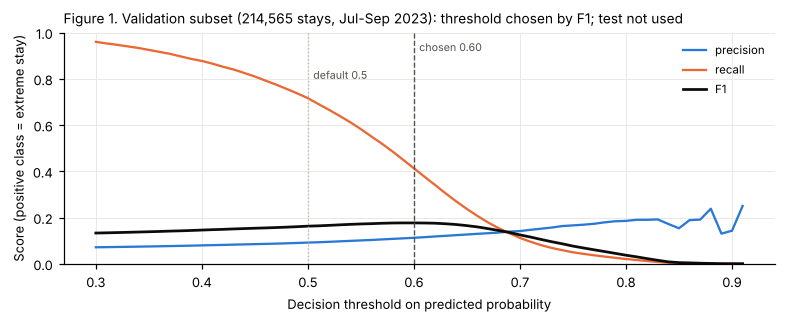

In [7]:
fig, ax = plt.subplots(figsize=(7.2, 3.0))
ax.plot(curve.threshold, curve.precision, color=BLUE, label="precision")
ax.plot(curve.threshold, curve.recall, color=ORANGE, label="recall")
ax.plot(curve.threshold, curve.F1, color=INK, lw=1.8, label="F1")
ax.axvline(THRESHOLD, color=INK2, ls="--", lw=0.9); ax.text(THRESHOLD+0.005, 0.92, f"chosen {THRESHOLD:.2f}", fontsize=7, color=INK2)
ax.axvline(0.5, color=GREY, ls=":", lw=0.9); ax.text(0.505, 0.80, "default 0.5", fontsize=7, color=INK2)
ax.set_xlabel("Decision threshold on predicted probability"); ax.set_ylabel("Score (positive class = extreme stay)"); ax.set_ylim(0, 1)
ax.set_title(f"Figure 1. Validation subset ({len(va):,} stays, Jul-Sep 2023): threshold chosen by F1; test not used")
ax.legend(frameon=False, fontsize=7.5); fig.tight_layout(); fig.savefig(FIG/"c2_fig1_validation_threshold.png"); plt.show()

## 6. Final evaluation on the test subset (one run)

Model, inputs, settings and threshold are now fixed. The test subset (admissions January-September 2024) is transformed with the frozen rules and evaluated **once**. The frozen fingerprint is checked before the metrics are computed.

In [8]:
Z["test"] = transform(S["test"])
assert params_fingerprint() == FP_FROZEN, "a frozen threshold changed"
te = Z["test"][Z["test"].LABEL.notna()]
y_te = te.LABEL.astype(int).values
p_te = model.predict_proba(te[ADM_FEATURES])[:, 1]
yhat_te = (p_te >= THRESHOLD).astype(int)
yhat_base = baseline_emergency(te)
test_tab = pd.DataFrame([metrics(y_te, yhat_te, f"model, threshold {THRESHOLD:.2f}"),
                         metrics(y_te, yhat_base, "baseline: flag every emergency admission"),
                         metrics(y_te, baseline_none(te), "trivial: flag nobody")]).set_index("rule")
test_tab.to_csv(OUT/"c2_05_test_metrics.csv")
print(f"Test stays: {len(Z['test']):,} | with a label: {len(te):,} | without a frozen cut-off (not evaluated): {Z['test'].LABEL.isna().sum():,}")
print(f"Test prevalence of extreme stays: {y_te.mean():.2%} | hospitals unseen in train: {(te.HOSP_ENC == 'UNSEEN_HOSPITAL').sum():,} test stays")
test_tab

Test stays: 655,321 | with a label: 655,093 | without a frozen cut-off (not evaluated): 228
Test prevalence of extreme stays: 6.12% | hospitals unseen in train: 12,267 test stays


,flagged %,TP,FP,FN,TN,precision,recall,F1,accuracy
rule,,,,,,,,,
"model, threshold 0.60",20.58,14271,120529,25807,494486,0.1059,0.3561,0.1632,0.7766
baseline: flag every emergency admission,62.07,28139,378447,11939,236568,0.0692,0.7021,0.1260,0.4041
trivial: flag nobody,0.00,0,0,40078,615015,0.0000,0.0000,0.0000,0.9388


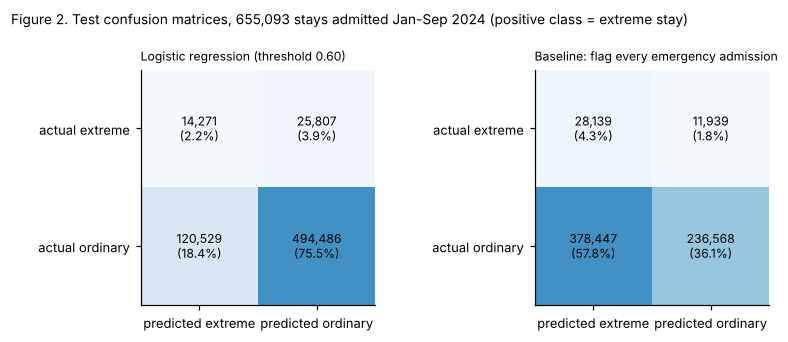

In [9]:
cm_m = confusion_matrix(y_te, yhat_te, labels=[1, 0]); cm_b = confusion_matrix(y_te, yhat_base, labels=[1, 0])
fig, axes = plt.subplots(1, 2, figsize=(7.4, 3.1))
for ax, cm, ttl in ((axes[0], cm_m, f"Logistic regression (threshold {THRESHOLD:.2f})"), (axes[1], cm_b, "Baseline: flag every emergency admission")):
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=cm.max()*1.6); ax.grid(False)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:,}\n({cm[i, j]/cm.sum():.1%})", ha="center", va="center", fontsize=8)
    ax.set_xticks([0, 1], ["predicted extreme", "predicted ordinary"]); ax.set_yticks([0, 1], ["actual extreme", "actual ordinary"])
    ax.set_title(ttl, fontsize=8)
fig.suptitle(f"Figure 2. Test confusion matrices, {len(te):,} stays admitted Jan-Sep 2024 (positive class = extreme stay)", x=0.01, ha="left", fontsize=9)
fig.tight_layout(); fig.savefig(FIG/"c2_fig2_test_confusion_matrices.png"); plt.show()

In [10]:
# What the model relies on: largest coefficients (odds ratios), from the model fitted on train
names = model.named_steps["prep"].get_feature_names_out()
coef = pd.Series(model.named_steps["clf"].coef_[0], index=names)
top = pd.concat([coef.nlargest(8), coef.nsmallest(5)]).to_frame("coefficient")
top["odds ratio"] = np.exp(top.coefficient)
top.index = top.index.str.replace("cat__", "").str.replace("num__", "")
top.round(3).to_csv(OUT/"c2_06_top_coefficients.csv"); top.round(3)

,coefficient,odds ratio
UNIT_EMBARAZO ALTO RIESGO OBSTÉTRICO (PATOLÓGICO),1.273,3.572
UNIT_PSIQUIATRÍA CORTA ESTADÍA,0.976,2.653
UNIT_UNIDAD EMERGENCIA (INDIFERENCIADO),0.928,2.530
UNIT_OFTALMOLOGÍA,0.744,2.105
HOSP_ENC_106102,0.687,1.987
PREVISION_FONASA INSTITUCIONAL - (MAI) A,0.678,1.970
UNIT_OTORRINOLARINGOLOGÍA,0.665,1.945
HOSP_ENC_113130,0.624,1.866
PREVISION_FONASA LIBRE ELECCIÓN (FMLE_B),-1.606,0.201
UNIT_PENSIONADO MATERNIDAD,-1.584,0.205


In [11]:
# Errors by admission type on test: where the model adds over the baseline
seg = te.assign(pred=yhat_te, base=yhat_base).groupby("TIPO_INGRESO").apply(lambda d: pd.Series({
    "stays": len(d), "prevalence %": d.LABEL.mean()*100,
    "model recall": recall_score(d.LABEL.astype(int), d.pred, zero_division=0), "model precision": precision_score(d.LABEL.astype(int), d.pred, zero_division=0),
    "baseline recall": recall_score(d.LABEL.astype(int), d.base, zero_division=0), "baseline precision": precision_score(d.LABEL.astype(int), d.base, zero_division=0)}),
    include_groups=False).sort_values("stays", ascending=False)
seg.round(3).to_csv(OUT/"c2_07_test_by_admission_type.csv"); seg.round(3)

,stays,prevalence %,model recall,model precision,baseline recall,baseline precision
TIPO_INGRESO,,,,,,
URGENCIA,406586.0,6.921,0.410,0.103,1.0,0.069
PROGRAMADA,137887.0,3.126,0.029,0.088,0.0,0.000
OBSTETRICA,110586.0,6.898,0.340,0.122,0.0,0.000
DESCONOCIDO,34.0,2.941,0.000,0.000,0.0,0.000


In [12]:
assert params_fingerprint() == FP_FROZEN
SUMMARY = {"train stays with label": len(tr), "validation stays with label": len(va), "test stays with label": len(te),
           "frozen fingerprint": FP_FROZEN, "threshold (from validation)": THRESHOLD,
           "test prevalence %": round(y_te.mean()*100, 2),
           "model F1": test_tab.iloc[0].F1, "baseline F1": test_tab.iloc[1].F1,
           "model recall": test_tab.iloc[0].recall, "baseline recall": test_tab.iloc[1].recall,
           "model precision": test_tab.iloc[0].precision, "baseline precision": test_tab.iloc[1].precision,
           "model flagged %": test_tab.iloc[0]["flagged %"], "baseline flagged %": test_tab.iloc[1]["flagged %"]}
pd.Series(SUMMARY).to_csv(OUT/"c2_08_summary.csv", header=["value"]); pd.Series(SUMMARY)

train stays with label                   421226
validation stays with label              214565
test stays with label                    655093
frozen fingerprint             7a96dae3b661e290
threshold (from validation)                 0.6
test prevalence %                          6.12
model F1                                 0.1632
baseline F1                               0.126
model recall                             0.3561
baseline recall                          0.7021
model precision                          0.1059
baseline precision                       0.0692
model flagged %                           20.58
baseline flagged %                        62.07
dtype: object

## 7. Interpretation

**What the results show (test, 655,093 stays admitted January-September 2024, prevalence of extreme stays 6.12%).**
- The model flags 20.6% of stays and finds 35.6% of the extreme stays (recall). Of the stays it flags, 10.6% become extreme (precision), 1.7 times the base rate.
- The baseline "flag every emergency admission" finds more extreme stays (recall 70.2%) but flags 62.1% of all stays, and only 6.9% of its flags are extreme stays, barely above the base rate.
- The model has the higher F1 (0.163 vs 0.126) and needs about a third of the flags. Per flagged patient, it is 1.5 times as likely to point at a real extreme stay. It also covers obstetric admissions (recall 34%), which the baseline misses by construction.
- Validation (0.177) and test (0.163) F1 are close, so the result holds when the model moves from 2023 to 2024 admissions.

**Why accuracy alone is insufficient.** "Flag nobody" has the highest accuracy on test (93.9%) and is useless: it finds no extreme stay. With 6% positives, accuracy is dominated by the ordinary stays, so we judge the rules by precision, recall and F1 for the positive class.

**Errors and their consequences (positive class = extreme stay).**
- *False negative* (25,807 on test): an extreme stay not flagged. Discharge planning starts late, the bed stays blocked, and the hospital loses the reason for building the model. This is the costlier error clinically.
- *False positive* (120,529): an ordinary stay flagged. A social worker or discharge nurse reviews a patient who would have left on time. It costs staff time, not patient harm, but at 20% of admissions it would overload a team; this is why we did not keep the 0.5 threshold (50% flagged on validation).

**Main limit.** Admission-time fields carry weak signal: precision is 11% at the chosen threshold and stays below about 25% even when recall falls close to zero (Figure 1). Most of what makes a stay extreme (complications, social discharge barriers, waiting for a bed elsewhere) happens after admission and is not in the file. The test set also lacks October-December 2024 and the encrypted patient identifier, so repeated patients across subsets cannot be checked (W2 risk L5). The model is an association: a flag does not prove that early discharge planning would shorten the stay; that needs a trial or a before/after study.

**Possible improvement.** Re-score each patient at 48-72 hours, adding information that exists by then but still before discharge (for example, transfer to an intensive or intermediate care unit, or theatre use), and validate it with the same chronological split. A second, cheaper step is a per-hospital threshold, since flag capacity is decided by each hospital.

**Use in the business decision.** As a first screen, the model is more useful than the emergency-admission rule because it concentrates discharge-planning effort on a smaller group with a higher hit rate. It is not accurate enough to decide anything on its own.

## 8. Contributions and AI use

**Member contributions.**

| Member | Contribution |
|---|---|
| Matías López | Led the notebook: data preparation, model training, validation and test evaluation. Reviewed the brief and the slides. |
| Cristóbal Ramírez | Led the brief and the presentation: structure, interpretation of results and figures. Reviewed and tested the notebook. |

**AI use.** Claude (Anthropic), in a claude.ai Project chat on 08-11-2026, read the C2 brief and rubric, the W2 notebook and the W2 feedback, and reviewed this notebook, the brief and the slides. The team chose the classification route and the project line, which continue from W1, C1 and W2.

How the suggestions were checked: the notebook was executed top to bottom without errors; the split counts are asserted equal to W2; the frozen cut-offs are compared value by value with the W2 table; an assertion stops the run if any post-admission field enters the inputs; the fingerprint of the frozen parameters is re-checked after validation and after test.

The team is responsible for every result and methodological choice in this notebook.